In [ ]:
# Install necessary packages
!pip install xgboost category_encoders scikit-learn matplotlib seaborn --quiet

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.experimental import enable_halving_search_cv
from sklearn.experimental import enable_halving_search_cv
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, precision_recall_curve, auc, roc_curve
import xgboost as xgb
import category_encoders as ce


In [ ]:
# importing the dataset
df = pd.read_csv("/content/drive/MyDrive/group_D/diabetic_data.csv")
# show the first five rows including all columns displayed
pd.set_option('display.max_columns', None)
df.head()


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,?,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,?,?,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,?,?,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,?,?,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,?,?,44,1,16,0,0,0,8,250.43,403,7,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,?,?,51,0,8,0,0,0,197,157,250,5,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      101766 non-null  object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    101766 non-null  object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                101766 non-null  object
 11  medical_specialty         101766 non-null  object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

In [ ]:
# List of independent variables
independent_vars = ["gender", "race", "age", "diabetesMed"]
outcome_var = "readmitted"

# Initialize an empty DataFrame for results
result = pd.DataFrame()

# Loop through each independent variable
for var in independent_vars:
    # Crosstab: distribution of outcome (0/1) per category of the variable
    ct = pd.crosstab(df[outcome_var], df[var], normalize='columns') * 100

    # Round to 1 decimal place
    ct = ct.round(1)

    # Rename columns to include variable name
    ct.columns = [f"{var}: {col}" for col in ct.columns]

    # Append to final result
    result = pd.concat([result, ct], axis=1)

# Reset index to make outcome (0/1) a column
result.reset_index(inplace=True)

# Display
print(result)

  readmitted  gender: Female  gender: Male  gender: Unknown/Invalid  race: ?  \
0        <30            11.2          11.1                      0.0      8.3   
1        >30            35.7          34.1                      0.0     23.7   
2         NO            53.1          54.9                    100.0     68.1   

   race: AfricanAmerican  race: Asian  race: Caucasian  race: Hispanic  \
0                   11.2         10.1             11.3            10.4   
1                   34.5         25.1             35.6            31.5   
2                   54.2         64.7             53.1            58.1   

   race: Other  age: [0-10)  age: [10-20)  age: [20-30)  age: [30-40)  \
0          9.6          1.9           5.8          14.2          11.2   
1         29.6         16.1          32.4          30.8          31.4   
2         60.8         82.0          61.8          55.0          57.3   

   age: [40-50)  age: [50-60)  age: [60-70)  age: [70-80)  age: [80-90)  \
0          10.

data cleaning

In [ ]:
# Drop columns with too many missing values
df.drop(['weight', 'payer_code', 'medical_specialty', 'max_glu_serum', 'A1Cresult'], axis=1, inplace=True)

# Drop irrelevant identifiers
df.drop(['encounter_id', 'patient_nbr'], axis=1, inplace=True)

# Drop rows with 'Unknown' or '?' entries
df = df.replace('?', np.nan)
df = df.dropna()

# Drop discharge disposition 11 (expired) and 13 (hospice)
df = df[~df['discharge_disposition_id'].isin([11, 13])]

# Encode readmission: NO=0, <30 or >30=1
df['readmitted'] = df['readmitted'].apply(lambda x: 0 if x == 'NO' else 1)


In [ ]:
df=df.drop_duplicates()
df.shape

(96051, 43)

Univariate Analysis

In [ ]:
#pie chart to show distribution of gender
import plotly.express as px
fig = px.pie(df, names="gender", title="Distribution of Gender")
fig.show()

In [ ]:
# bar chart to show age column
fig = px.histogram(df, x="age", title="Distribution of Age", color="age")
fig.show()

In [ ]:
#bar chart to show race column
fig = px.histogram(df, x="race", title="Distribution of Race", color="race")
fig.show()

In [ ]:
# box plot of "age"
fig = px.box(df, x="age", title="Age Distribution")
fig.show()

In [ ]:
# box plot of number of lab procedure
fig = px.box(df, x="num_lab_procedures", title="Number of Lab Procedures")
fig.show()

bivariate analysis

In [ ]:
# plot of "insulin" vs "readmission"
fig = px.histogram(df, x="insulin", color="readmitted", title="Insulin vs Readmission", barmode="group")
fig.show()

In [ ]:
#plot of "time_in_hospital" vs "readmited"
fig = px.histogram(df, x="time_in_hospital", color="readmitted", title="Time in Hospital vs Readmission", barmode="group")
fig.show()


removing out liers

In [ ]:
# Limit IQR outlier removal to numerical columns only
numerical_cols = df.select_dtypes(include=['number']).columns

Q1 = df[numerical_cols].quantile(0.25)
Q3 = df[numerical_cols].quantile(0.75)
IQR = Q3 - Q1

# Create a mask for rows without outliers in numerical columns
filter_mask = ~((df[numerical_cols] < (Q1 - 1.5 * IQR)) |
                (df[numerical_cols] > (Q3 + 1.5 * IQR))).any(axis=1)

# Filter the original DataFrame using the mask
df = df[filter_mask]


In [ ]:
# box plot of number of lab procedure
fig = px.box(df, x="num_lab_procedures", title="Number of Lab Procedures")
fig.show()

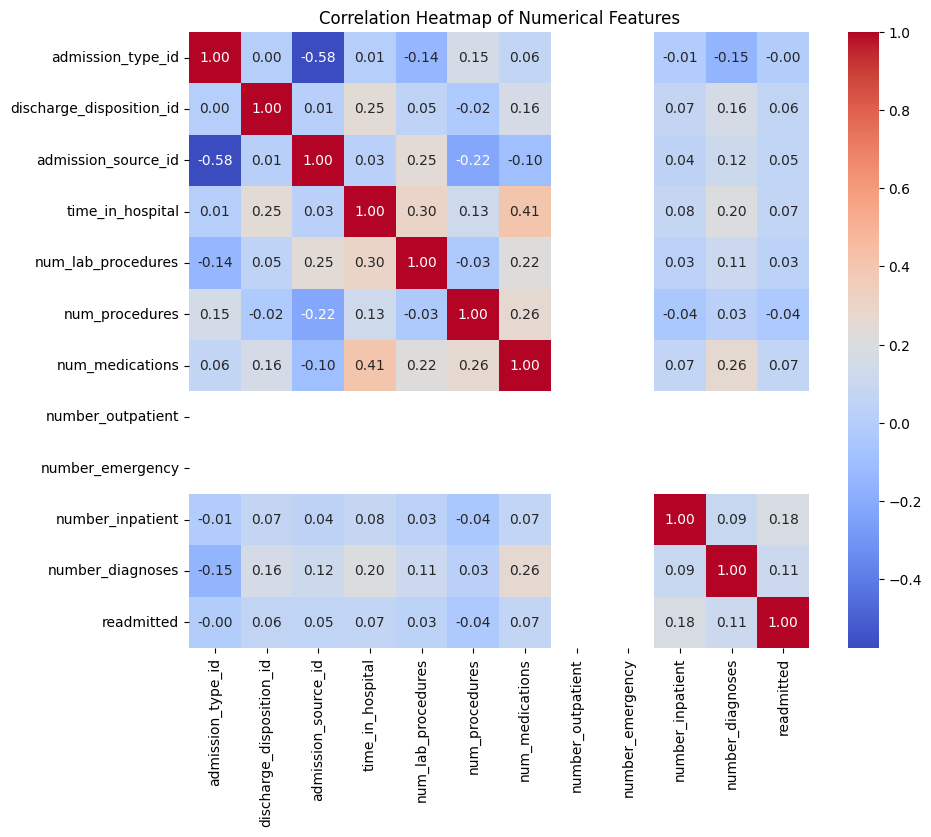

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Select only numerical columns
#numerical_df = df.select_dtypes(include='number')
numerical_df = df.select_dtypes(include=['number'])


# Compute correlation matrix
corr_matrix = numerical_df.corr()

# Plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap of Numerical Features")
plt.show()

Feature Engineering

In [ ]:
# Separate features
categorical = df.select_dtypes(include='object').columns.tolist()
# 'readmitted' was encoded to numerical, so it's not in categorical
# categorical.remove('readmitted') # This line caused the error

numerical = df.select_dtypes(exclude='object').columns.tolist()
# Remove 'readmitted' from the numerical list
numerical.remove('readmitted')

# Custom encoding: One-hot for low cardinality; Target encoding for diagnoses
low_card = [col for col in categorical if df[col].nunique() < 50 and 'diag' not in col]
high_card = ['diag_1', 'diag_2', 'diag_3']

# Define transformers
preprocessor = ColumnTransformer([
    ('target', ce.TargetEncoder(), high_card),
    ('onehot', ce.OneHotEncoder(use_cat_names=True), low_card),
    ('scale', StandardScaler(), numerical)
])

In [ ]:
# create a pie chart to show the distribution of the "Outcome" variables
import plotly.express as px
fig = px.pie(df, names="readmitted", title="Distribution of Outcome")
fig.show()

Train-Test Split

In [ ]:
X = df.drop('readmitted', axis=1)
y = df['readmitted']

X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.2, random_state=0)


#Train Models (ElasticNet, RF, XGBoost)

 Elastic Net Logistic Regression

In [ ]:
pipe_log = Pipeline([
    ('preprocess', preprocessor),
    ('clf', LogisticRegression(penalty='elasticnet', solver='saga', l1_ratio=0.5, max_iter=5000, random_state=0))
])
pipe_log.fit(X_train, y_train)


Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('target', TargetEncoder(),
                                                  ['diag_1', 'diag_2',
                                                   'diag_3']),
                                                 ('onehot',
                                                  OneHotEncoder(use_cat_names=True),
                                                  ['race', 'gender', 'age',
                                                   'metformin', 'repaglinide',
                                                   'nateglinide',
                                                   'chlorpropamide',
                                                   'glimepiride',
                                                   'acetohexamide', 'glipizide',
                                                   'glyburide', 'tolbutamide',
                                                   'pioglitazone',
                                                   'rosiglitazone', 'acarbose...
                                                 ('scale', StandardScaler(),
                                                  ['admission_type_id',
                                                   'discharge_disposition_id',
                                                   'admission_source_id',
                                                   'time_in_hospital',
                                                   'num_lab_procedures',
                                                   'num_procedures',
                                                   'num_medications',
                                                   'number_outpatient',
                                                   'number_emergency',
                                                   'number_inpatient',
                                                   'number_diagnoses'])])),
                ('clf',
                 LogisticRegression(l1_ratio=0.5, max_iter=5000,
                                    penalty='elasticnet', random_state=0,
                                    solver='saga'))])

 Random Forest

In [ ]:
pipe_rf = Pipeline([
    ('preprocess', preprocessor),
    ('clf', RandomForestClassifier(n_estimators=100, max_depth=10, random_state=0))
])
pipe_rf.fit(X_train, y_train)


Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('target', TargetEncoder(),
                                                  ['diag_1', 'diag_2',
                                                   'diag_3']),
                                                 ('onehot',
                                                  OneHotEncoder(use_cat_names=True),
                                                  ['race', 'gender', 'age',
                                                   'metformin', 'repaglinide',
                                                   'nateglinide',
                                                   'chlorpropamide',
                                                   'glimepiride',
                                                   'acetohexamide', 'glipizide',
                                                   'glyburide', 'tolbutamide',
                                                   'pioglitazone',
                                                   'rosiglitazone', 'acarbose...
                                                   'metformin-pioglitazone',
                                                   'change', 'diabetesMed']),
                                                 ('scale', StandardScaler(),
                                                  ['admission_type_id',
                                                   'discharge_disposition_id',
                                                   'admission_source_id',
                                                   'time_in_hospital',
                                                   'num_lab_procedures',
                                                   'num_procedures',
                                                   'num_medications',
                                                   'number_outpatient',
                                                   'number_emergency',
                                                   'number_inpatient',
                                                   'number_diagnoses'])])),
                ('clf', RandomForestClassifier(max_depth=10, random_state=0))])

 XGBoost

In [ ]:
pipe_xgb = Pipeline([
    ('preprocess', preprocessor),
    ('clf', xgb.XGBClassifier(use_label_encoder=False, eval_metric='logloss', max_depth=6, n_estimators=100, random_state=0))
])
pipe_xgb.fit(X_train, y_train)


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning:

[22:50:44] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.




Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('target', TargetEncoder(),
                                                  ['diag_1', 'diag_2',
                                                   'diag_3']),
                                                 ('onehot',
                                                  OneHotEncoder(use_cat_names=True),
                                                  ['race', 'gender', 'age',
                                                   'metformin', 'repaglinide',
                                                   'nateglinide',
                                                   'chlorpropamide',
                                                   'glimepiride',
                                                   'acetohexamide', 'glipizide',
                                                   'glyburide', 'tolbutamide',
                                                   'pioglitazone',
                                                   'rosiglitazone', 'acarbose...
                               feature_types=None, gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=None,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=6, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=100, n_jobs=None,
                               num_parallel_tree=None, random_state=0, ...))])

Evaluate Models

Elastic Net Accuracy: 0.6239, AUROC: 0.6510, AUPRC: 0.5608
Random Forest Accuracy: 0.6273, AUROC: 0.6581, AUPRC: 0.5650
XGBoost Accuracy: 0.6190, AUROC: 0.6443, AUPRC: 0.5446


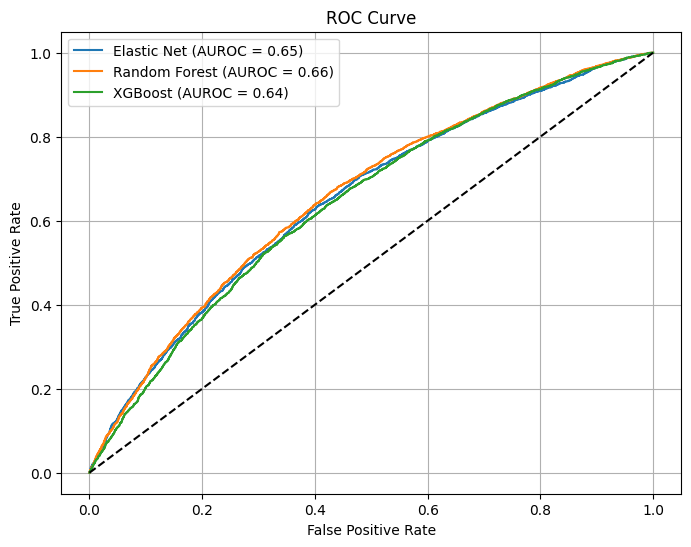

In [ ]:
def evaluate(model, X_test, y_test, name='Model'):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_prob)
    precision, recall, _ = precision_recall_curve(y_test, y_prob)
    pr_auc = auc(recall, precision)

    print(f"{name} Accuracy: {acc:.4f}, AUROC: {roc_auc:.4f}, AUPRC: {pr_auc:.4f}")

    # ROC curve
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, label=f'{name} (AUROC = {roc_auc:.2f})')

# Plot ROC for all
plt.figure(figsize=(8, 6))
evaluate(pipe_log, X_test, y_test, 'Elastic Net')
evaluate(pipe_rf, X_test, y_test, 'mRandom Forest')
evaluate(pipe_xgb, X_test, y_test, 'XGBoost')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC Curve'); plt.legend(); plt.grid(True); plt.show()


#Feature Importance

Logistic Regression

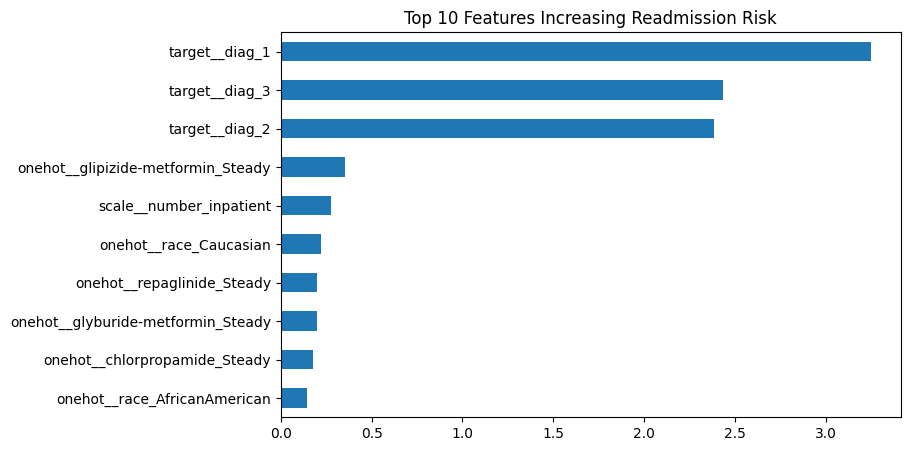

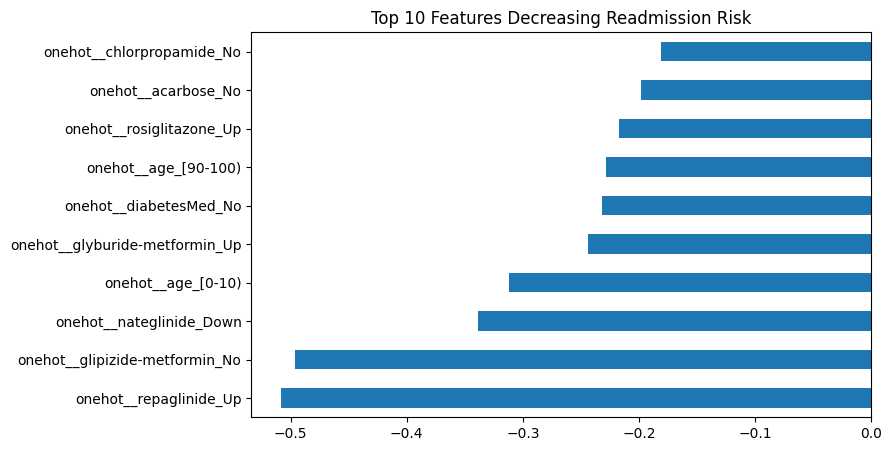

In [ ]:
# Extract coefficients
features = pipe_log.named_steps['preprocess'].get_feature_names_out()
weights = pipe_log.named_steps['clf'].coef_[0]
coefs = pd.Series(weights, index=features).sort_values()

plt.figure(figsize=(8, 5))
coefs.tail(10).plot(kind='barh', title='Top 10 Features Increasing Readmission Risk')
plt.show()

plt.figure(figsize=(8, 5))
coefs.head(10).plot(kind='barh', title='Top 10 Features Decreasing Readmission Risk')
plt.show()


For XGBoost

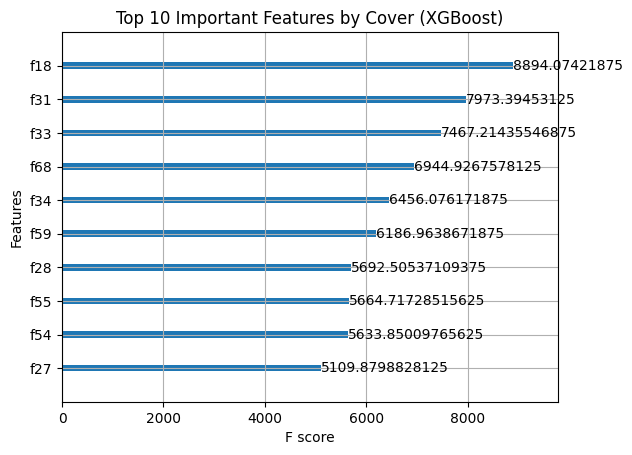

In [ ]:
booster = pipe_xgb.named_steps['clf']
xgb.plot_importance(booster, max_num_features=10, importance_type='cover')
plt.title('Top 10 Important Features by Cover (XGBoost)')
plt.show()


In [ ]:
transformed_feature_names = pipe_xgb.named_steps['preprocess'].get_feature_names_out()
print(transformed_feature_names)

['target__diag_1' 'target__diag_2' 'target__diag_3'
 'onehot__race_Caucasian' 'onehot__race_AfricanAmerican'
 'onehot__race_Other' 'onehot__race_Hispanic' 'onehot__race_Asian'
 'onehot__gender_Female' 'onehot__gender_Male'
 'onehot__gender_Unknown/Invalid' 'onehot__age_[80-90)'
 'onehot__age_[70-80)' 'onehot__age_[30-40)' 'onehot__age_[60-70)'
 'onehot__age_[40-50)' 'onehot__age_[10-20)' 'onehot__age_[50-60)'
 'onehot__age_[0-10)' 'onehot__age_[20-30)' 'onehot__age_[90-100)'
 'onehot__metformin_Steady' 'onehot__metformin_No' 'onehot__metformin_Up'
 'onehot__metformin_Down' 'onehot__repaglinide_No'
 'onehot__repaglinide_Steady' 'onehot__repaglinide_Up'
 'onehot__repaglinide_Down' 'onehot__nateglinide_No'
 'onehot__nateglinide_Steady' 'onehot__nateglinide_Down'
 'onehot__nateglinide_Up' 'onehot__chlorpropamide_No'
 'onehot__chlorpropamide_Steady' 'onehot__chlorpropamide_Down'
 'onehot__chlorpropamide_Up' 'onehot__glimepiride_No'
 'onehot__glimepiride_Steady' 'onehot__glimepiride_Up'
 'on

Hyper_parameter tunning

/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_search.py:317: UserWarning:

The total space of parameters 50 is smaller than n_iter=5357. Running 50 iterations. For exhaustive searches, use GridSearchCV.

/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_search.py:317: UserWarning:

The total space of parameters 27 is smaller than n_iter=5357. Running 27 iterations. For exhaustive searches, use GridSearchCV.

/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_search.py:317: UserWarning:

The total space of parameters 81 is smaller than n_iter=5357. Running 81 iterations. For exhaustive searches, use GridSearchCV.

/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning:

[22:55:21] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.




ElasticNet (Tuned) Accuracy: 0.6113, AUROC: 0.6349, AUPRC: 0.5488
Random Forest (Tuned) Accuracy: 0.6239, AUROC: 0.6565, AUPRC: 0.5627
XGBoost (Tuned) Accuracy: 0.5962, AUROC: 0.6155, AUPRC: 0.5158


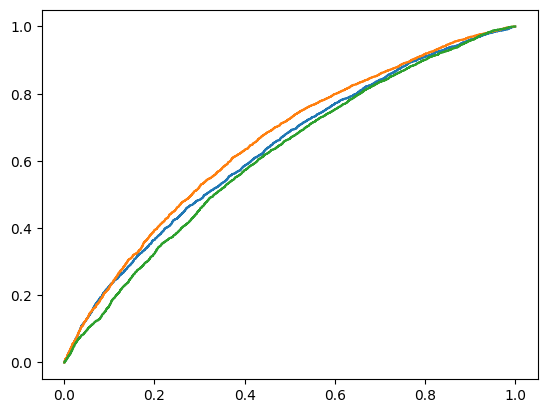

In [ ]:
from sklearn.experimental import enable_halving_search_cv  # noqa
from sklearn.model_selection import HalvingRandomSearchCV

# Define hyperparameter grids for each model
param_grid_log = {
    'clf__C': np.logspace(-4, 4, 10),
    'clf__l1_ratio': np.linspace(0, 1, 5)
}

param_grid_rf = {
    'clf__n_estimators': [50, 100, 200],
    'clf__max_depth': [5, 10, 15],
    'clf__min_samples_split': [2, 5, 10]
}

param_grid_xgb = {
    'clf__n_estimators': [50, 100, 200],
    'clf__max_depth': [3, 6, 9],
    'clf__learning_rate': [0.01, 0.1, 0.2],
    'clf__subsample': [0.6, 0.8, 1.0]
}

# Wrap models in pipelines again for tuning
pipe_log = Pipeline([
    ('preprocess', preprocessor),
    ('clf', LogisticRegression(penalty='elasticnet', solver='saga', max_iter=5000, random_state=0))
])

pipe_rf = Pipeline([
    ('preprocess', preprocessor),
    ('clf', RandomForestClassifier(random_state=0))
])

pipe_xgb = Pipeline([
    ('preprocess', preprocessor),
    ('clf', xgb.XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=0))
])

# Create HalvingRandomSearchCV objects
tuner_log = HalvingRandomSearchCV(pipe_log, param_grid_log, scoring='roc_auc', cv=2, random_state=0, n_jobs=-1)
tuner_rf = HalvingRandomSearchCV(pipe_rf, param_grid_rf, scoring='roc_auc', cv=2, random_state=0, n_jobs=-1)
tuner_xgb = HalvingRandomSearchCV(pipe_xgb, param_grid_xgb, scoring='roc_auc', cv=2, random_state=0, n_jobs=-1)

# Output just the definition of these tuning objects so they can be added to the notebook file next
"Hyperparameter tuning objects created for Logistic Regression, Random Forest, and XGBoost."
# Fit models
tuner_log.fit(X_train, y_train)
tuner_rf.fit(X_train, y_train)
tuner_xgb.fit(X_train, y_train)

# Evaluate tuned models
evaluate(tuner_log, X_test, y_test, "ElasticNet (Tuned)")
evaluate(tuner_rf, X_test, y_test, "Random Forest (Tuned)")
evaluate(tuner_xgb, X_test, y_test, "XGBoost (Tuned)")
